# Машинное обучение, ФКН ВШЭ

## Практическое задание 4. Классификация

### Общая информация
Дата выдачи: 16.11.2024

Мягкий дедлайн: 28.11.2024

Жесткий дедлайн: 02.12.2024

### О задании

В этом задании вы:
- ознакомитесь с тем, что происходит "внутри" метода опорных векторов и логистической регрессии
- познакомитесь с калибровкой вероятности
- изучите методы трансформации переменных и методы отбора признаков
- попробуете оценить экономический эффект модели

----

#### Самостоятельная оценка результатов

Для удобства проверки, исходя из набора решенных задач, посчитайте свою максимальную оценку.

**Оценка**:

### Оценивание и штрафы

Каждая из задач имеет определенную «стоимость» (указана в скобках около задачи). Максимально допустимая оценка за работу — 10 баллов.

Задание выполняется самостоятельно. «Похожие» решения считаются плагиатом и все задействованные студенты (в том числе те, у кого списали) не могут получить за него больше 0 баллов (подробнее о плагиате см. на странице курса). Если вы нашли решение какого-то из заданий (или его часть) в открытом источнике, необходимо указать ссылку на этот источник в отдельном блоке в конце вашей работы (скорее всего вы будете не единственным, кто это нашел, поэтому чтобы исключить подозрение в плагиате, необходима ссылка на источник).

Неэффективная реализация кода может негативно отразиться на оценке.

### Формат сдачи

Для сдачи задания переименуйте получившийся файл *.ipynb в соответствии со следующим форматом: homework-practice-04-linclass-__Username__.ipynb, где Username — ваша фамилия и имя на латинице именно в таком порядке (например, homework-practice-04-linclass-__IvanovIvan__.ipynb).

# Часть 1. SVM, LR и калибровка вероятностей (2 балла + 0.5 бонус)

In [ ]:
import numpy as np
import pandas as pd
# import polars as pl
import matplotlib.pyplot as plt
%matplotlib inline

pd.set_option('display.max_rows', 100)
pd.set_option('display.max_columns', 100)
# pl.Config().set_tbl_rows(100)
# pl.Config().set_tbl_cols(100)

#### __Задание 1.1  Сравнение методов__ (0.5 балла)



Сгенерируем синтетические данные.

In [ ]:
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split

# фиксируем random_state для воспроизводимости результатов
X, y = make_classification(
    n_samples=10000, n_features=10, n_informative=5, n_redundant=5, random_state=42
)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

__Случайный классификатор__

Для начала зададим самую простую модель, которая на каждом объекте выдаёт случайный ответ. По тестовой выборке вычислим AUC-ROC, AUC-PR.

In [ ]:
from sklearn.dummy import DummyClassifier
random_classifier = DummyClassifier(strategy='uniform', random_state=42).fit(X_train, y_train)
y_random = random_classifier.predict_proba(X_test)[:,1]
y_random

array([0.5, 0.5, 0.5, ..., 0.5, 0.5, 0.5])

**Вопрос:** решаем задачу бинарной классификации, но y\_random содержит какие-то дробные числа, а не 0/1. Почему?



**Ответ**: # your answer here

*Ниже приведен **пример** работы* со встроенными функциями `sklearn` для отрисовки ROC и PR кривых, сохранения метрик. Пайплайн можно изменять как вам удобно.

In [ ]:
from sklearn.metrics import average_precision_score

from sklearn.metrics import precision_recall_curve
from sklearn.metrics import PrecisionRecallDisplay

from sklearn.metrics import roc_auc_score
from sklearn.metrics import RocCurveDisplay

Random Classifier metrics
AUC-PR: 0.5057
AUC-ROC: 0.5000


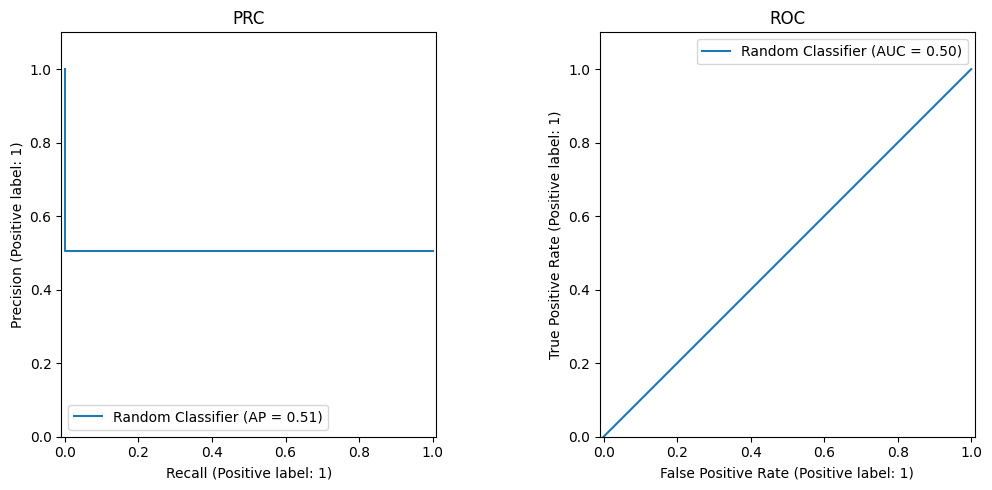

In [ ]:
def depict_pr_roc(y_true, y_pred, classifier_name='Some Classifier', ax=None):
    if ax is None:
        fig, ax = plt.subplots(1, 2, figsize=(11, 5))

    print(classifier_name, 'metrics')
    PrecisionRecallDisplay.from_predictions(y_true, y_pred, ax=ax[0], name=classifier_name)
    print('AUC-PR: %.4f' % average_precision_score(y_true, y_pred))
    ax[0].set_title("PRC")
    ax[0].set_ylim(0, 1.1)

    RocCurveDisplay.from_predictions(y_true, y_pred, ax=ax[1], name=classifier_name)
    print('AUC-ROC: %.4f' % roc_auc_score(y_true, y_pred))
    ax[1].set_title("ROC")
    ax[1].set_ylim(0, 1.1)

    plt.tight_layout()
    plt.legend()


depict_pr_roc(y_test, y_random, 'Random Classifier')

In [ ]:
# dataframe для сравнения
# методов классификации по метрикам
df_metrics = pd.DataFrame(
    columns=['auc_pr', 'roc_auc_score', 'reg_const']
)
precision, recall, _ = precision_recall_curve(y_test, y_random)
# добавление очередной строки с характеристиками метода
df_metrics.loc['Random Classifier'] = [
      average_precision_score(y_test, y_random),
      roc_auc_score(y_test, y_random),
      0,
]

# по аналогии результаты следующих экспериментов можно будет собрать в табличку
df_metrics

,auc_pr,roc_auc_score,reg_const
Random Classifier,0.505667,0.5,0.0


__Support Vector Machine (Linear Kernel)__

Обучите метод опорных векторов.

Подберите параметр регуляризации `C` с точки зрения AUC-PR (можете воспользоваться кросс-валидацией или отделить валидационную выборку от обучающей).


In [ ]:
from sklearn.svm import LinearSVC

# your code here
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.metrics import average_precision_score, make_scorer
from sklearn.datasets import make_classification
from sklearn.preprocessing import StandardScaler
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.2, random_state=42)

param_grid = {'C': np.logspace(-3, 3, 7)}
grid_search = GridSearchCV(LinearSVC(random_state=42, max_iter=5000),
                           param_grid,
                           cv=5,
                           n_jobs=-1)
grid_search.fit(X_train, y_train)


print(f"Лучшее значение C: {grid_search.best_params_['C']:.4f}")
print(f"Лучшее AUC-PR (CV): {grid_search.best_score_:.4f}")

best_model = grid_search.best_estimator_
y_scores = best_model.decision_function(X_test)
test_pr = average_precision_score(y_test, y_scores)
print(f"AUC-PR на тестовой выборке: {test_pr:.4f}")

Лучшее значение C: 0.0100
Лучшее AUC-PR (CV): 0.7868
AUC-PR на тестовой выборке: 0.8279


  На тестовой части:
  - постройте ROC и PR кривые,
  - посчитайте AUC-ROC, AUC-PR

Linear SVM metrics
AUC-PR: 0.8279
AUC-ROC: 0.8474


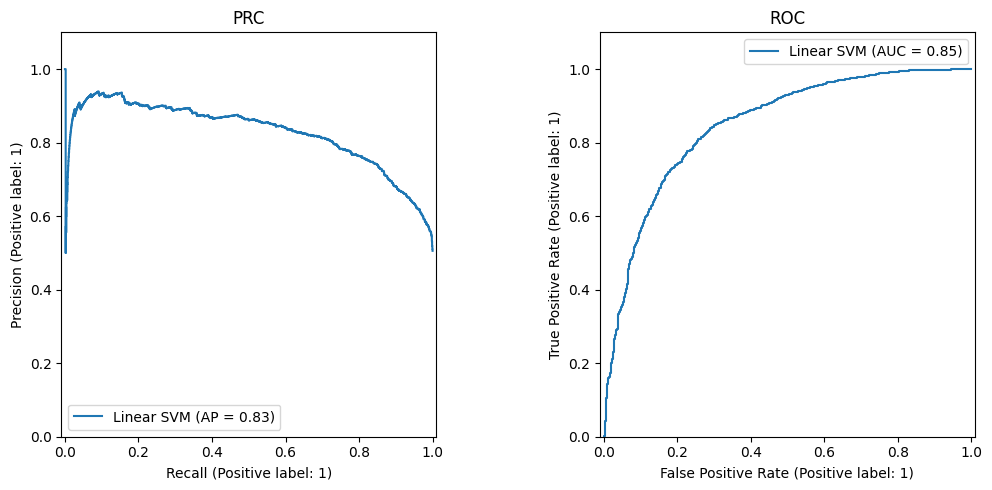

In [ ]:
# your code here
depict_pr_roc(y_test, y_scores, classifier_name='Linear SVM')

Проанализируйте, как себя ведут обе кривые:
- Что происходит при увеличении порога? Как бы вы это проинтерпретировали?
- Монотонные ли кривые? Как вы это объясните?

Сравните AUC-ROC и AUC-PR для вашей модели с этими же метриками для случайного классификатора.

In [ ]:
# your code here

__Logistic Regression__


Аналогичное задание для логистической регрессии с L2 регуляризатором:


*   подберите гиперпараметр C, используя метрику AUC-PR
*   нарисуйте ROC, PR кривые для тестовой части
*   выведите метрики для тестовых данных и сравните их с результатами случайного классификатора



In [ ]:
from sklearn.linear_model import LogisticRegression

# your code here
logreg = LogisticRegression(penalty='l2', solver='lbfgs', max_iter=1000, random_state=42)

grid = GridSearchCV(logreg, param_grid,
                    cv=5, n_jobs=-1)
grid.fit(X_train, y_train)

best_logreg = grid.best_estimator_
best_C = grid.best_params_['C']
print(f"Лучший C: {best_C:.4f}")
print(f"Лучший AUC-PR на CV: {grid.best_score_:.4f}")

y_probs = best_logreg.predict_proba(X_test)[:, 1]

Лучший C: 1.0000
Лучший AUC-PR на CV: 0.7879


Нарисуйте ROC, PR кривые для тестовой части для всех 3 классификаторов на одном графике

Linear SVM: AUC-PR = 0.8279, AUC-ROC = 0.8474
Logistic Regression: AUC-PR = 0.8274, AUC-ROC = 0.8477
Random Classifier: AUC-PR = 0.5057, AUC-ROC = 0.5000


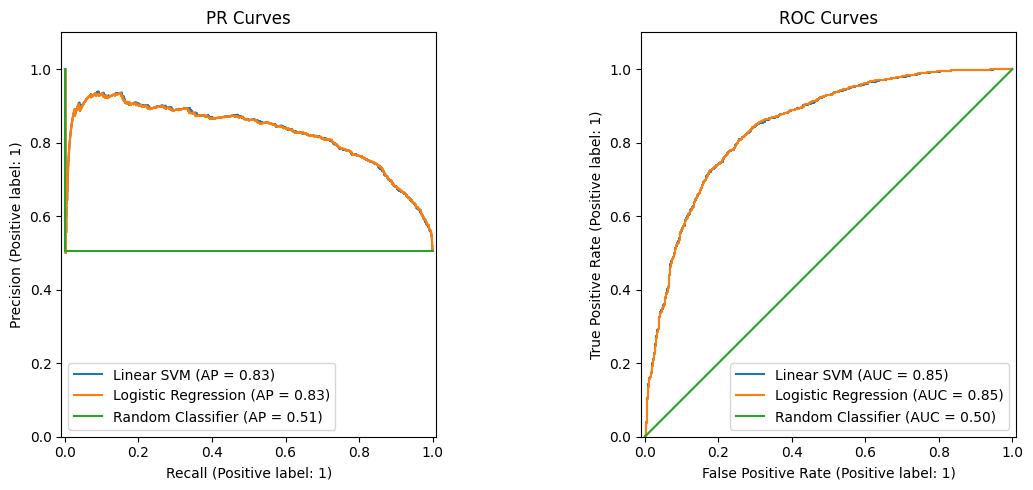

In [ ]:
# your code here
fig, (ax_pr, ax_roc) = plt.subplots(1, 2, figsize=(12, 5))

# Функция для добавления кривых на существующие оси (без повторной легенды)
def add_curves(y_true, y_pred, model_name, ax_pr, ax_roc):
    # Добавляем PR-кривую
    PrecisionRecallDisplay.from_predictions(y_true, y_pred, ax=ax_pr, name=model_name)
    # Добавляем ROC-кривую
    RocCurveDisplay.from_predictions(y_true, y_pred, ax=ax_roc, name=model_name)
    # Выводим метрики
    print(f"{model_name}: AUC-PR = {average_precision_score(y_true, y_pred):.4f}, AUC-ROC = {roc_auc_score(y_true, y_pred):.4f}")


add_curves(y_test, y_scores, "Linear SVM", ax_pr, ax_roc)


add_curves(y_test, y_probs, "Logistic Regression", ax_pr, ax_roc)


add_curves(y_test, y_random, "Random Classifier", ax_pr, ax_roc)

# Оформление графиков
ax_pr.set_title("PR Curves")
ax_pr.set_ylim(0, 1.1)
ax_roc.set_title("ROC Curves")
ax_roc.set_ylim(0, 1.1)
ax_pr.legend()
ax_roc.legend()
plt.tight_layout()
plt.show()

**Вопрос:** Сравните результаты LR и SVM с точки зрения всех вычисленных критериев качества, объясните различия (если они есть).



**Ответ:** # your answer here

#### __Задание 1.2. Визуализация в подходах SVM, LR__ (0.5 балла)



В названии метода опорных векторов присутствуют некоторые "опорные векторы". По сути, это объекты из обучающей выборки, которые задали положение разделяющей гиперплоскости.

* Сгенерируйте синтетические данные с помощью `make_classification` __с 2 признаками__, обучите на нём метод опорных векторов. Не забудьте зафиксировать seed для воспроизводимости

* Визуализируйте разделяющую прямую, все объекты и выделите опорные векторы. Ниже есть шаблоны, можете воспользоваться ими, либо написать своё

In [ ]:
# your code here
from sklearn.datasets import make_classification
from sklearn.svm import SVC

X, y = make_classification(
    n_samples=100,
    n_features=2,
    n_informative=2,
    n_redundant=0,
    n_clusters_per_class=1,
    random_state=42
)


model = SVC(kernel='linear', C=1.0)
model.fit(X, y)

SVC(kernel='linear')

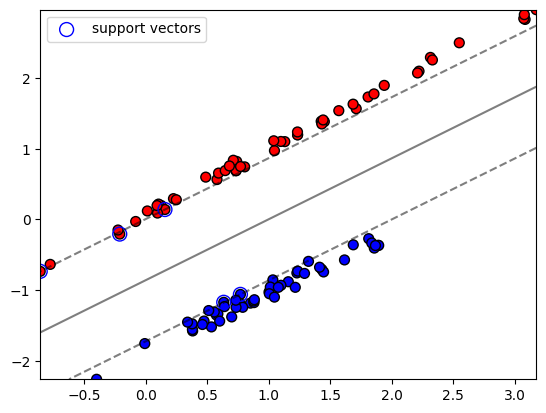

In [ ]:
def plot_svm_2D(X, y, model,  plot_support=True):

    # создали сетку
    xx = np.linspace(X[:,0].min(), X[:,0].max(), 30)
    yy = np.linspace(X[:,1].min(), X[:,1].max(), 30)
    YY, XX = np.meshgrid(yy, xx)
    xy = np.vstack([XX.ravel(), YY.ravel()]).T

    # Ответы модели для сетки для отрисовки разделяющей прямой
    Z = model.decision_function(xy).reshape(XX.shape)# your code here

    plt.contour(XX, YY, Z, colors='k', levels=[-1, 0, 1], alpha=0.5, linestyles=['--', '-', '--'])
    # Отрисовали выборку
    plt.scatter(
        X[:, 0], X[:, 1], c=y, cmap='bwr', edgecolors='k', s=50 # your code here
    )

    # Отрисовали опорные векторы
    if plot_support:
        plt.scatter(
            model.support_vectors_[:, 0], model.support_vectors_[:, 1], # your code here
            label='support vectors',
            s=100,
            linewidth=1,
            edgecolor="blue",
            facecolors='none'
        )

    plt.legend()

plot_svm_2D(X, y, model)

**Вопрос:** какие объекты выделяются как "опорные"?



**Ответ:** # your answer here

В отличие от метода опорных векторов, логистическая регрессия не пытается построить разделяющую гиперплоскость с максимальным отступом, а приближает в каждой точке пространства объектов вероятность положительных ответов $p(y=+1|x)$. Попробуйте нарисовать это распределение на плоскости, не забудьте отметить на ней все объекты.

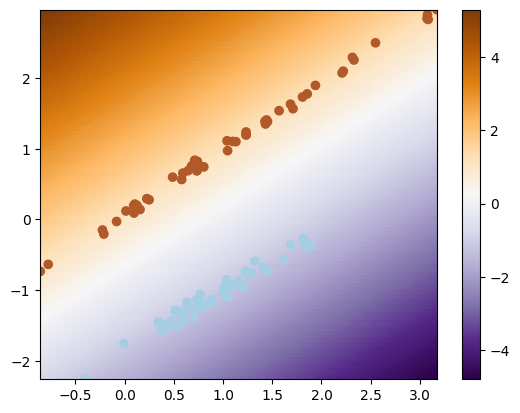

In [ ]:
def plot_logreg_2D(X, y, model):

    # создали сетку
    xx = np.linspace(X[:,0].min(), X[:,0].max(), 100)
    yy = np.linspace(X[:,1].min(), X[:,1].max(), 100)
    YY, XX = np.meshgrid(yy, xx)
    xy = np.vstack([XX.ravel(), YY.ravel()]).T

    # Ответы модели для сетки для отрисовки распределения
    Z = model.decision_function(xy).reshape(XX.shape)# your code here
    Z = Z.reshape((xx.shape[0], -1)).T

    image = plt.imshow(
        Z,
        interpolation='nearest',
        extent=(xx.min(), xx.max(), yy.min(), yy.max()),
        aspect='auto',
        origin='lower',
        cmap=plt.cm.PuOr_r
    )

    #Отрисовали выборку
    plt.scatter(
        X[:, 0], X[:, 1], c=y, # your code here
        cmap=plt.cm.Paired
    )

    plt.colorbar(image)

plot_logreg_2D(X, y, model)

**Вопрос:** Как на картинке визуализирована область, где модель не уверена ($p(y=+1|x) = 0.5$)? Как это обосновать теоритечески?



**Ответ:** # your answer here

#### __Задание 2. Калибровка вероятностей__ (1 балл)



Перейдём к оценке качества выдаваемых алгоритмами вероятностей. Начнём с калибровочных кривых.

Допустим, алгоритм возвращает некоторые числа от нуля до единицы. Хорошо ли они оценивают вероятность?

Хорошо откалиброванный  классификатор должен выдавать значения так, чтобы среди образцов, для которых он дал значение, близкое к $\alpha$, примерно $\alpha * 100 \%$ фактически принадлежали к положительному классу. (Например, если классификатор выдает 0.3 для некоторых, то 30% из них должны принадлежать классу 1)

Для построения калибровочной криовой используем следующий алгоритм:

Разобьем отрезок $[0, 1]$ на несколько маленьких отрезков одинаковой длины.

Рассмотрим $i$-й отрезок с границами $[a_i, b_i]$ и предсказания $p_1, p_2, \dots, p_k$, которые попали в него. Пусть им соответствуют истинные ответы $y_1, y_2, \dots, y_k$. Если алгоритм выдает корректные вероятности, то среди этих истинных ответов должно быть примерно $(a_i + b_i) / 2$ единиц. Иными словами, если нарисовать кривую, у которой по оси X отложены центры отрезков, а по оси Y — доли единичных ответов этих в отрезках, то она должна оказаться диагональной.

Ниже приведена функция, которая должна рисовать такие кривые. В ней допущено две ошибки — найдите и исправьте их.

In [ ]:
def plot_calibration_curve(y_test, preds):
    bin_middle_points = []
    bin_real_ratios = []
    n_bins = 10
    for i in range(n_bins):
        l = 1.0 / n_bins * i
        r = 1.0 / n_bins * (i + 1)
        bin_middle_points.append((l + r) / 2)
        bin_real_ratios.append(np.mean(y_test[(preds >= l) & (preds < r)] == 1))
    # plt.figure(figsize=(6,6))
    plt.plot(bin_middle_points, bin_real_ratios)
    plt.ylim([-0.05, 1.05])
    plt.grid()

Сгенерируйте синтетические данные аналогично использованным в самом первом задании. Постройте калибровочные кривые на тестовой части для логистической регрессии и метода опорных векторов (не забудьте перевести его предсказания в $[0;1]$).

Отрисуйте калибровочную кривую идеально откалиброванной модели (диагональ)

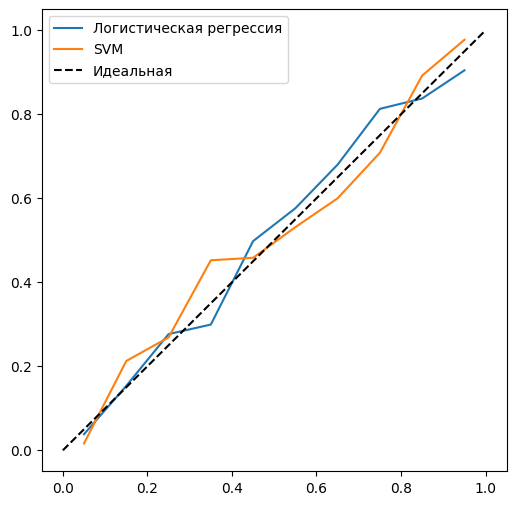

In [ ]:
# your code here
X, y = make_classification(
    n_samples=10000, n_features=10, n_informative=5, n_redundant=5, random_state=42
)


X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)


logreg = LogisticRegression(random_state=42)
logreg.fit(X_train, y_train)
probs_logreg = logreg.predict_proba(X_test)[:, 1]


svm = SVC(probability=True, random_state=42)
svm.fit(X_train, y_train)
probs_svm = svm.predict_proba(X_test)[:, 1]



plt.figure(figsize=(6,6))
plot_calibration_curve(y_test, probs_logreg)
plot_calibration_curve(y_test, probs_svm)
plt.plot([0,1], [0,1], 'k--', label='Идеально калиброванная')
plt.legend(['Логистическая регрессия', 'SVM', 'Идеальная'])
plt.show()

**Вопрос**: хорошо ли откалиброваны кривые для SVM, логистической регрессии? Подумайте, как это следует из вида кривой

**Ответ:** # your answer here

Из формальных способов в этом убедиться есть знакомый вам LogLoss, который напрямую оценивает вероятности,
$$\text{LogLoss} = -\frac{1}{N}\sum_{i} \sum_{k \in {0. 1}}\log p_k[y_i = k]$$
а так же BrierScore, который подсчитывает отклонение между получившейся вероятностью и реальным значением таргета.
$$\text{BrierScore} = \frac{1}{N}\sum_{i} (p_i - y_i)^2$$
Посмотрите на них тоже и сделайте вывод

In [ ]:
# your code here
from sklearn.metrics import log_loss, brier_score_loss

# Логистическая регрессия
log_loss_logreg = log_loss(y_test, probs_logreg)
brier_logreg = brier_score_loss(y_test, probs_logreg)

# SVM
log_loss_svm = log_loss(y_test, probs_svm)
brier_svm = brier_score_loss(y_test, probs_svm)

print("LogLoss")
print(f"Логистическая регрессия: {log_loss_logreg:.4f}")
print(f"SVM: {log_loss_svm:.4f}")

print("Brier Score")
print(f"Логистическая регрессия: {brier_logreg:.4f}")
print(f"SVM: {brier_svm:.4f}")

LogLoss
Логистическая регрессия: 0.4859
SVM: 0.1701
Brier Score
Логистическая регрессия: 0.1586
SVM: 0.0460


Изучите распределение ответов классификаторов при помощи гистограмм







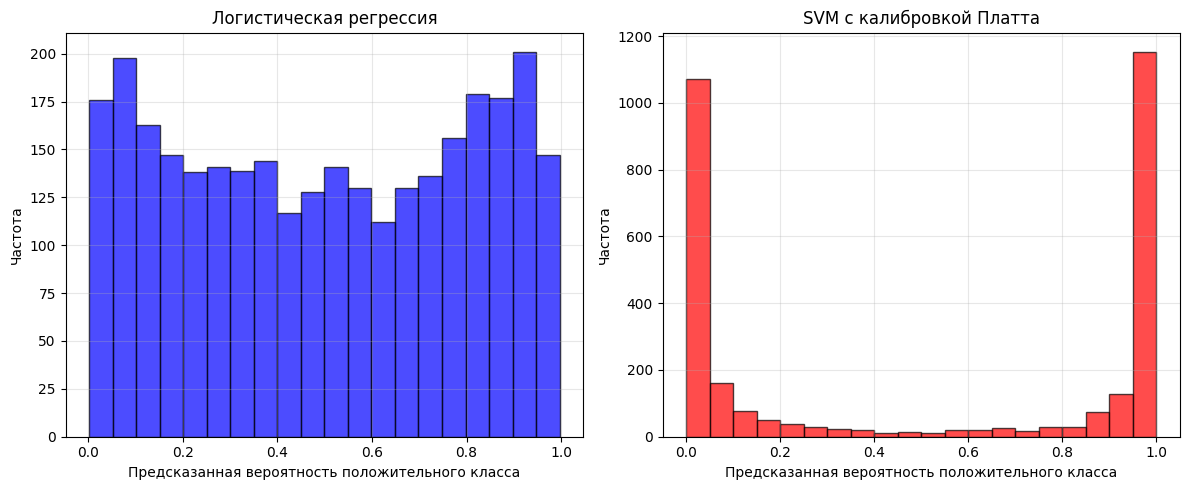

In [ ]:
# your code here
plt.figure(figsize=(12, 5))

# Гистограмма для логистической регрессии
plt.subplot(1, 2, 1)
plt.hist(probs_logreg, bins=20, edgecolor='black', alpha=0.7, color='blue')
plt.xlabel('Предсказанная вероятность положительного класса')
plt.ylabel('Частота')
plt.title('Логистическая регрессия')
plt.grid(True, alpha=0.3)

# Гистограмма для SVM
plt.subplot(1, 2, 2)
plt.hist(probs_svm, bins=20, edgecolor='black', alpha=0.7, color='red')
plt.xlabel('Предсказанная вероятность положительного класса')
plt.ylabel('Частота')
plt.title('SVM с калибровкой Платта')
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

**Вопрос:** Чем они различаются? Чем вы можете объяснить это?

**Ответ:** # your answer here

Воспользуйтесь `CalibratedClassifierCV` из `sklearn` для калибровки вероятностей метода опорных векторов на обучении и постройте с его помощью  предсказания для тестовой выборки.

In [ ]:
# your code here

**Вопрос:** Улучшились ли калибровочная кривая и качество калибровки?

**Ответ:** # your answer here

##### __Бонус: Авторское решение__ (0.5 балла)

Реализуйте свою функцию для калибровки вероятностей, используя любой из известных подходов. Кратко опишите ваш подход и продемонстрируйте результаты. Ключевые слова для вдохновения: `Platt`, `Isotonic`.

In [ ]:
# your code here

# Часть 2. Обработка категориальных переменных (4 балла + 1.5 бонус)

Как мы знаем, перекодировать категориальную переменную в список чисел (к примеру 1, 2, 3, ..., n) плохо, поскольку это бы задало на множестве ее значений некоторый порядок, не имеющий смысла.

В этой части мы рассмотрим два основных способа обработки категориальных значений:
- One-hot-кодирование
- Счётчики (CTR, mean-target кодирование, ...) — каждый категориальный признак заменяется на среднее значение целевой переменной по всем объектам, имеющим одинаковое значение в этом признаке.

Начнём с one-hot-кодирования. Допустим наш категориальный признак $f_j(x)$ принимает значения из множества $C=\{c_1, \dots, c_m\}$. Заменим его на $m$ бинарных признаков $b_1(x), \dots, b_m(x)$, каждый из которых является индикатором одного из возможных категориальных значений:
$$
b_i(x) = [f_j(x) = c_i]
$$

#### __Подготовка данных__

*(бесценный шаг)*

Разберем датасет [покупок велосипедов](https://www.kaggle.com/datasets/heeraldedhia/bike-buyers/): даны признаки покупателя, требуется предсказать, купит ли он/она велосипед



Замените пропуски в категориальных переменных на новую категорию (`'undefined'`)

Разделите признаки на 2 таблицы: категориальные и числовые признаки

In [ ]:
import kagglehub

path = kagglehub.dataset_download("heeraldedhia/bike-buyers") +  "/bike_buyers.csv"

Using Colab cache for faster access to the 'bike-buyers' dataset.


In [ ]:
# Прочитаем датасет
# your code here
df = pd.read_csv(path)


# Заменим пропуски категориальных переменных
# your code here
categorical_cols = df.select_dtypes(include=['object']).columns
for col in categorical_cols:
    df[col].fillna(df[col].mode()[0], inplace=True)

# Отделим X и y
# your code here
y = df['Purchased Bike']
X = df.drop('Purchased Bike', axis=1)

# Разделим на категориальные признаки и числовые
X_numerical = X[['Income', 'Children', 'Cars', 'Age']]# your code here
X_categorical = X[['Marital Status', 'Gender', 'Education','Commute Distance', 'Occupation', 'Home Owner', 'Region']]# your code here

/tmp/ipykernel_54240/1938694260.py:10: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df[col].fillna(df[col].mode()[0], inplace=True)


В начале поработаем только с категориальными признаками

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X_categorical, y, test_size=0.25, random_state=777, stratify=y)

#### __Задание 3. OrdinalEncoder__  (0.5 балла)

Закодируйте категориальные признаки с помощью `OrdinalEncoder`. Посчитайте качество (в этом задании будем работать c __`AUC-PR`__) при применении логистической регрессии. Замерьте время, потребовавшееся на обучение модели, с учетом кодирования признаков.

In [ ]:
def plot_pr_curve(y_true, y_scores, classifier_name='Logistic Regression'):
    """
    Строит Precision-Recall кривую и выводит AUC-PR.

    Parameters:
    y_true : array-like, истинные метки (0/1)
    y_scores : array-like, предсказанные вероятности положительного класса
    classifier_name : str, название классификатора для подписи
    """
    pr_display = PrecisionRecallDisplay.from_predictions(
        y_true, y_scores, name=classifier_name, pos_label=1
    )
    auc_pr = average_precision_score(y_true, y_scores)
    print(f'{classifier_name} metrics')
    print(f'AUC-PR: {auc_pr:.4f}')
    plt.title("Precision-Recall Curve")
    plt.ylim(0, 1.05)
    plt.tight_layout()
    plt.show()

Logistic Regression metrics
AUC-PR: 0.5959


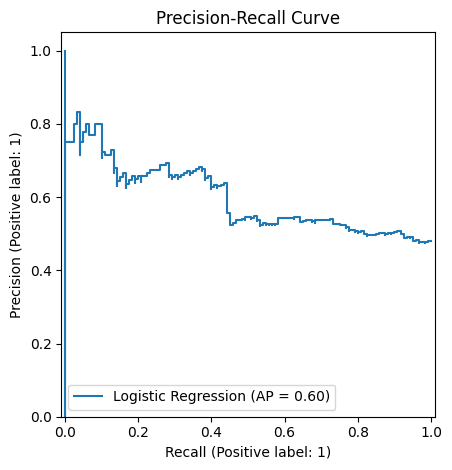

Время (кодирование + обучение): 0.019 секунд


In [ ]:
# your code here
import time
from sklearn.preprocessing import OrdinalEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score

# Кодирование категориальных признаков
start_time = time.time()
encoder = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)


X_train_encoded = encoder.fit_transform(X_train)
X_test_encoded = encoder.transform(X_test)

# Преобразование целевой переменной в числовой формат (Yes = 1, No = 0)
y_train_bin = (y_train == 'Yes').astype(int)
y_test_bin = (y_test == 'Yes').astype(int)

# Обучение логистической регрессии
model = LogisticRegression(max_iter=1000, random_state=777)
model.fit(X_train_encoded, y_train_bin)

# Предсказание вероятностей и расчёт AUC-PR
y_pred_proba = model.predict_proba(X_test_encoded)[:, 1]
auc_pr = average_precision_score(y_test_bin, y_pred_proba)

end_time = time.time()
elapsed_time = end_time - start_time

plot_pr_curve(y_test_bin, y_pred_proba, classifier_name='Logistic Regression')
print(f"Время (кодирование + обучение): {elapsed_time:.3f} секунд")

#### __Задание 4. One-Hot Encoding__ (0.5 балла)



Закодируйте все категориальные признаки с помощью one-hot-кодирования. Обучите логистическую регрессию и посмотрите, как изменилось качество модели (в сравнении с тем, что было до кодирования). Измерьте время, потребовавшееся на кодирование категориальных признаков и обучение модели.

Время one-hot кодирования: 0.013 сек
Время обучения модели: 0.009 сек
Общее время: 0.022 сек
Logistic Regression metrics
AUC-PR: 0.6708


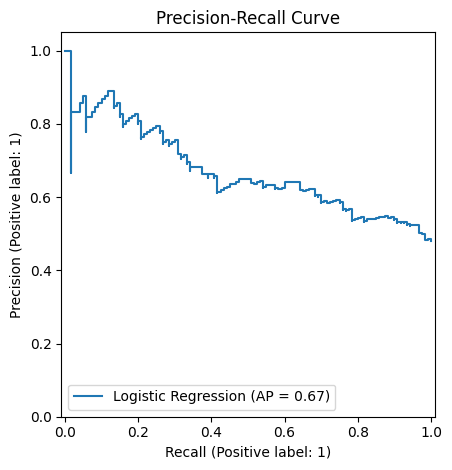

In [ ]:
# your code here
from sklearn.preprocessing import OneHotEncoder
start_encode = time.time()

encoder = OneHotEncoder(sparse_output=False, handle_unknown='ignore')
X_train_ohe = encoder.fit_transform(X_train)
X_test_ohe = encoder.transform(X_test)

end_encode = time.time()
time_encode = end_encode - start_encode

# Обучение логистической регрессии
start_train = time.time()

model = LogisticRegression(max_iter=1000, random_state=777)
model.fit(X_train_ohe, y_train_bin)

end_train = time.time()
time_train = end_train - start_train

# Предсказание вероятностей
y_pred_proba = model.predict_proba(X_test_ohe)[:, 1]

# Оценка качества
auc_pr = average_precision_score(y_test_bin, y_pred_proba)

print(f"Время one-hot кодирования: {time_encode:.3f} сек")
print(f"Время обучения модели: {time_train:.3f} сек")
print(f"Общее время: {time_encode + time_train:.3f} сек")
plot_pr_curve(y_test_bin, y_pred_proba, classifier_name='Logistic Regression')

Как можно заметить, one-hot-кодирование может сильно увеличивать количество признаков. Это сказывается на объеме необходимой памяти, особенно, если некоторый признак имеет большое количество значений.


#### __Задание 5. Mean-target Encoding__ (1 балл)

> Проблемы разрастания числа признаков можно избежать в другом способе кодирования категориальных признаков — mean-target encoding (для простоты будем называть это __счётчиками__). Сравним эффективность методов в рамках нашей маркетинговой задачи.

> Основная идея в том, что важны не сами категории, а значения целевой переменной, которые имеют объекты этой категории. Каждый категориальный признак мы заменим средним значением целевой переменной по всем объектам этой же категории:

$$
g_j(x, X) = \frac{\sum_{i=1}^{\ell} [f_j(x) = f_j(x_i)][y_i = +1]}{\sum_{i=1}^{\ell} [f_j(x) = f_j(x_i)]}
$$

Закодируйте категориальные переменные с помощью счётчиков (ровно так, как описано выше, без каких-либо хитростей). Обучите логистическую регрессию и посмотрите на качество модели на тестовом множестве.

Сравните время обучения с предыдущими экспериментами (с учетом кодирования признаков).

Время mean-target кодирования: 0.022 сек
Время обучения модели: 0.009 сек
Общее время: 0.031 сек
Logistic Regression metrics
AUC-PR: 0.6832


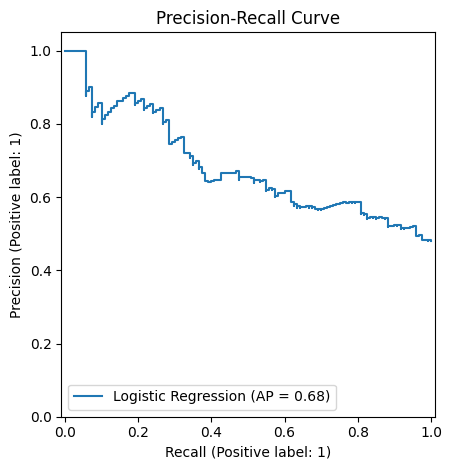

In [ ]:
# your code here
global_mean = y_train_bin.mean()

# Mean-target encoding
start_encode = time.time()

# Копируем данные для преобразования
X_train_encoded = X_train.copy()
X_test_encoded = X_test.copy()

# Для каждого категориального столбца
for col in X_train.columns:
    # Вычисляем среднее значение target для каждой категории в обучающей выборке
    target_means = y_train_bin.groupby(X_train[col]).mean()

    # Применяем к обучающей выборке
    X_train_encoded[col] = X_train[col].map(target_means)

    # Для тестовой выборки: если категория не встречалась в обучении, ставим global_mean
    X_test_encoded[col] = X_test[col].map(target_means).fillna(y_train_bin)

end_encode = time.time()
time_encode = end_encode - start_encode

# Обучение логистической регрессии
start_train = time.time()

model = LogisticRegression(max_iter=1000, random_state=777)
model.fit(X_train_encoded, y_train_bin)

end_train = time.time()
time_train = end_train - start_train

# Предсказание вероятностей
y_pred_proba = model.predict_proba(X_test_encoded)[:, 1]

# Оценка качества
auc_pr = average_precision_score(y_test_bin, y_pred_proba)

print(f"Время mean-target кодирования: {time_encode:.3f} сек")
print(f"Время обучения модели: {time_train:.3f} сек")
print(f"Общее время: {time_encode + time_train:.3f} сек")
plot_pr_curve(y_test_bin, y_pred_proba, classifier_name='Logistic Regression')

_______

__Методы борьбы с переобучением счетчиков__


Отметим, что mean-target encoding признаки сами по себе являются классификаторами и, обучаясь на них, мы допускаем "утечку" целевой переменной в признаки. Это ведёт к __переобучению__, поэтому считать такие признаки необходимо таким образом, чтобы при вычислении для конкретного объекта его __целевая метка не использовалась__.

Это можно делать следующими способами:
1. Вычислять значение счётчика по всем объектам расположенным выше в датасете (например, если у нас выборка отсортирована по времени).
2. Вычислять по фолдам, то есть делить выборку на некоторое количество частей и подсчитывать значение признаков по всем фолдам кроме текущего (как делается в кросс-валидации).
3. Внесение некоторого шума в посчитанные признаки.

#### __Задание 6. Пошумим__  (0.5 балла)

Реализуйте корректное вычисление счётчиков самым простым способом — добавление шума к значениям.  При этом постарайтесь найти баланс между борьбой с переобучением и сохранением полезности признаков. Снова обучите логистическую регрессию, оцените качество.

Время mean-target кодирования с шумом: 0.020 сек
Время обучения модели: 0.009 сек
Общее время: 0.029 сек
Logistic Regression metrics
AUC-PR: 0.6824


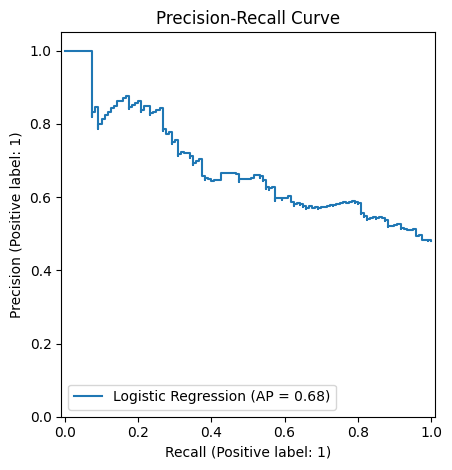

In [ ]:
# your code here
global_mean = y_train_bin.mean()

# Mean-target encoding с добавлением шума (только на обучающую выборку)
start_encode = time.time()

X_train_encoded = X_train.copy()
X_test_encoded = X_test.copy()

# Параметр шума (подбираем для баланса между борьбой с переобучением и сохранением полезности)
noise_std = 0.02  # стандартное отклонение шума (можно регулировать)

for col in X_train.columns:
    # Вычисляем среднее целевой переменной для каждой категории
    target_means = y_train_bin.groupby(X_train[col]).mean()

    # Применяем к обучающей выборке
    X_train_encoded[col] = X_train[col].map(target_means)

    # Добавляем шум только к обучающей выборке (для регуляризации)
    np.random.seed(777)  # для воспроизводимости
    noise = np.random.normal(0, noise_std, size=len(X_train_encoded))
    X_train_encoded[col] = X_train_encoded[col] + noise

    # Для тестовой выборки: неизвестные категории заменяем глобальным средним (без шума)
    X_test_encoded[col] = X_test[col].map(target_means).fillna(y_train_bin)

end_encode = time.time()
time_encode = end_encode - start_encode

# Обучение логистической регрессии
start_train = time.time()

model = LogisticRegression(max_iter=1000, random_state=777)
model.fit(X_train_encoded, y_train_bin)

end_train = time.time()
time_train = end_train - start_train

# Предсказание вероятностей
y_pred_proba = model.predict_proba(X_test_encoded)[:, 1]

# Оценка качества
auc_pr = average_precision_score(y_test_bin, y_pred_proba)

print(f"Время mean-target кодирования с шумом: {time_encode:.3f} сек")
print(f"Время обучения модели: {time_train:.3f} сек")
print(f"Общее время: {time_encode + time_train:.3f} сек")
plot_pr_curve(y_test_bin, y_pred_proba, classifier_name='Logistic Regression')

**Вопрос:** Сделайте выводы. Помогло ли добавление шума? Почему?

**Ответ:** # your answer here

#### __Задание 7. Сглаживание счетчиков__  (1 балл)

> Теперь ответим на следующий вопрос: что будет, если некоторая категория встречается в выборке всего несколько раз? По этой причине производится сглаживание счётчиков. Например, на практике хорошие результаты показывает использование сглаживания средним по всей выборке:
$$
g_j(x, X) = \frac{\sum_{i=1}^{\ell} [f_j(x) = f_j(x_i)][y_i = +1] + C \times \text{global_mean}}{\sum_{i=1}^{\ell} [f_j(x) = f_j(x_i)] + C}
$$
где $\text{global_mean}$ — доля объектов положительного класса в выборке, $C$ — параметр, определяющий степень сглаживания (можно использовать 10 или подобрать для каждого признака свой). Идея в том, что мы "разбавляем" среднее значение по категории глобальным средним значением. И тем меньше, чем большее количество объектов этой категории встречается в выборке.

> Вместо среднего значения целевой переменной для сглаживания можно использовать любое другое значение от 0 до 1 (этот параметр иногда называют $prior$). Можно сделать несколько признаков с разными значениями параметра. На практике в задачах бинарной классификации полезными бывают даже отрицательные значения!

Добавьте сглаживание, описанное выше и повторите эксперименты. Подберите $C$, чтобы качество было лучше, чем при использовании One-Hot-Encoding


In [ ]:
# your code here
from sklearn.metrics import average_precision_score
from sklearn.model_selection import cross_val_score
global_mean = y_train_bin.mean()

C_values = [0.1, 1, 5, 10, 20, 50, 100]
best_C = None
best_score = -1
model = LogisticRegression(max_iter=1000, random_state=777)

print("Подбор параметра C на кросс-валидации (AUC-PR):")
for C in C_values:
    X_train_enc = X_train.copy()
    for col in X_train.columns:
        agg = y_train_bin.groupby(X_train[col]).agg(['sum', 'count'])
        smooth_vals = (agg['sum'] + C * global_mean) / (agg['count'] + C)
        X_train_enc[col] = X_train[col].map(smooth_vals)
    scores = cross_val_score(model, X_train_enc, y_train_bin, cv=5,
                             scoring='average_precision', error_score='raise')
    mean_score = scores.mean()
    print(f"C = {C:5.1f} -> AUC-PR: {mean_score:.4f} (+/- {scores.std():.4f})")
    if mean_score > best_score:
        best_score = mean_score
        best_C = C

print(f"\nЛучший C: {best_C} (AUC-PR = {best_score:.4f})")

start_time = time.time()

X_train_enc = X_train.copy()
X_test_enc = X_test.copy()
for col in X_train.columns:
    agg = y_train_bin.groupby(X_train[col]).agg(['sum', 'count'])
    smooth_vals = (agg['sum'] + best_C * global_mean) / (agg['count'] + best_C)
    X_train_enc[col] = X_train[col].map(smooth_vals)
    X_test_enc[col] = X_test[col].map(smooth_vals).fillna(global_mean)

model.fit(X_train_enc, y_train_bin)
y_pred_proba = model.predict_proba(X_test_enc)[:, 1]
auc_pr_test = average_precision_score(y_test_bin, y_pred_proba)
time_total = time.time() - start_time

print(f"\nВремя кодирования + обучения: {time_total:.3f} сек")
print(f"AUC-PR на тесте: {auc_pr_test:.4f}")

Подбор параметра C на кросс-валидации (AUC-PR):
C =   0.1 -> AUC-PR: 0.6216 (+/- 0.0404)
C =   1.0 -> AUC-PR: 0.6217 (+/- 0.0412)
C =   5.0 -> AUC-PR: 0.6210 (+/- 0.0408)
C =  10.0 -> AUC-PR: 0.6209 (+/- 0.0423)
C =  20.0 -> AUC-PR: 0.6187 (+/- 0.0418)
C =  50.0 -> AUC-PR: 0.6170 (+/- 0.0420)
C = 100.0 -> AUC-PR: 0.6123 (+/- 0.0441)

Лучший C: 1 (AUC-PR = 0.6217)

Время кодирования + обучения: 0.079 сек
AUC-PR на тесте: 0.6823


#### **Задание 8. Числовые или категориальные?**  (0.5 балла)

Теперь добавим числовые признаки к счётчикам (тем, которые дали наибольший прирост качества).


Проверьте их на наличие выбросов и заполните пропуски средним или медианой, подумайте, что лучше в условиях наших данных



In [ ]:
# your code here
X_categorical_train = X_categorical.loc[X_train.index]
X_categorical_test = X_categorical.loc[X_test.index]
X_num_train = X_numerical.loc[X_train.index]
X_num_test = X_numerical.loc[X_test.index]

medians = X_num_train.median()
X_num_train_filled = X_num_train.fillna(medians)
X_num_test_filled = X_num_test.fillna(medians)

mask = pd.Series(True, index=X_num_train.index)

for col in X_num_train.columns:
    Q1 = X_num_train[col].quantile(0.25)
    Q3 = X_num_train[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    col_mask = (X_num_train[col] >= lower_bound) & (X_num_train[col] <= upper_bound)
    mask &= col_mask
    print(f"{col}: удалено {sum(~col_mask)} выбросов")

# Применяем маску ко всем частям данных (обучающие и тестовые)
X_num_train = X_num_train[mask]
X_categorical_train_clean = X_categorical_train[mask]
y_train_clean = y_train[mask]

Income: удалено 10 выбросов
Children: удалено 6 выбросов
Cars: удалено 48 выбросов
Age: удалено 9 выбросов


 Сейчас для числовых признаков мы ищем линейную зависимость, что в общем случае  может быть неверной гипотезой. Тем не менее, у этих признаков есть довольно много уникальных значений (сколько?), поэтому применять к ним one-hot кодирование может оказаться излишним. Попробуйте закодировать эти признаки с помощью счетчиков. Стало ли лучше?

In [ ]:
# your code here
global_mean = y_train_bin.mean()


def mean_target_encoding_smooth(X_train, y_train, X_test, C, global_mean):
    X_train_enc = X_train.copy()
    X_test_enc = X_test.copy()
    for col in X_train.columns:
        agg = y_train.groupby(X_train[col]).agg(['sum', 'count'])
        smooth_vals = (agg['sum'] + C * global_mean) / (agg['count'] + C)
        X_train_enc[col] = X_train[col].map(smooth_vals)
        X_test_enc[col] = X_test[col].map(smooth_vals).fillna(global_mean)
    return X_train_enc, X_test_enc


C_values = [0.1, 1, 5, 10, 20, 50, 100, 200]
best_C = None
best_score = -1
model = LogisticRegression(max_iter=1000, random_state=777, solver='lbfgs')

print("Подбор параметра C на кросс-валидации (AUC-PR):")
for C in C_values:
    X_train_enc, _ = mean_target_encoding_smooth(
        X_categorical_train, y_train_bin,
        X_categorical_test, C, global_mean
    )
    scores = cross_val_score(model, X_train_enc, y_train_bin, cv=5,
                             scoring='average_precision', error_score='raise')
    mean_score = scores.mean()
    print(f"C = {C:5.1f} -> AUC-PR: {mean_score:.4f} (+/- {scores.std():.4f})")
    if mean_score > best_score:
        best_score = mean_score
        best_C = C

print(f"\nЛучший C: {best_C} (CV AUC-PR = {best_score:.4f})")


start_time = time.time()
X_train_cat_enc, X_test_cat_enc = mean_target_encoding_smooth(
    X_categorical_train, y_train_bin,
    X_categorical_test, best_C, global_mean
)


model.fit(X_train_cat_enc, y_train_bin)
y_pred_proba = model.predict_proba(X_test_cat_enc)[:, 1]
auc_pr = average_precision_score(y_test_bin, y_pred_proba)
elapsed = time.time() - start_time

print(f"\nРезультат после удаления выбросов и Mean-target Encoding (C={best_C}):")
print(f"Время кодирования + обучения: {elapsed:.3f} сек")
print(f"AUC-PR на тесте: {auc_pr:.4f}")

# Сравнение с One-Hot Encoding
from sklearn.preprocessing import OneHotEncoder
encoder_ohe = OneHotEncoder(sparse_output=False, handle_unknown='ignore')
X_train_ohe = encoder_ohe.fit_transform(X_categorical_train)
X_test_ohe = encoder_ohe.transform(X_categorical_test)
model_ohe = LogisticRegression(max_iter=1000, random_state=777)
model_ohe.fit(X_train_ohe, y_train_bin)
y_pred_ohe = model_ohe.predict_proba(X_test_ohe)[:, 1]
auc_pr_ohe = average_precision_score(y_test_bin, y_pred_ohe)
print(f"\nOne-Hot Encoding (без выбросов): AUC-PR = {auc_pr_ohe:.4f}")
print(f"Разница Mean-target vs One-Hot: {auc_pr - auc_pr_ohe:.4f}")

Подбор параметра C на кросс-валидации (AUC-PR):
C =   0.1 -> AUC-PR: 0.6216 (+/- 0.0404)
C =   1.0 -> AUC-PR: 0.6217 (+/- 0.0412)
C =   5.0 -> AUC-PR: 0.6210 (+/- 0.0408)
C =  10.0 -> AUC-PR: 0.6209 (+/- 0.0423)
C =  20.0 -> AUC-PR: 0.6187 (+/- 0.0418)
C =  50.0 -> AUC-PR: 0.6170 (+/- 0.0420)
C = 100.0 -> AUC-PR: 0.6123 (+/- 0.0441)
C = 200.0 -> AUC-PR: 0.6088 (+/- 0.0476)

Лучший C: 1 (CV AUC-PR = 0.6217)

Результат после удаления выбросов и Mean-target Encoding (C=1):
Время кодирования + обучения: 0.080 сек
AUC-PR на тесте: 0.6823

One-Hot Encoding (без выбросов): AUC-PR = 0.6708
Разница Mean-target vs One-Hot: 0.0116


> __Замечание.__ Усложнение методов вычисления счётчиков не делают результаты модели гарантированно лучше. Особенно с учётом того, что логистическая регрессия не такая сложная модель, чтобы переобучаться. Поэтому вы необязательно должны были получать на каждом шаге всё лучшие и лучшие результаты (но необходимые результаты у вас должны были получиться).



Как мы могли пронаблюдать, счётчики являются конкурентной альтернативой one-hot-кодированию. Опишите, какие плюсы и минусы использования счётчиков по сравнению с one-hot-кодированием вы заметили.

__Ответ:__ # your answer here

# Часть 3. Отбор признаков (2 балла)

Загрузим данные [UCI Adult Dataset](https://archive.ics.uci.edu/ml/datasets/Adult). Этот набор данных содержит информацию о годовых доходах отдельных людей. В качестве признакового описания используется различная информация о человеке (образование, профессия, брачный статус и т.д.). Целевая переменная является бинарной: больше ли годовой доход 50K долларов или нет.

In [ ]:
!wget https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.data

--2026-06-03 18:57:53--  https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.data
Resolving archive.ics.uci.edu (archive.ics.uci.edu)... 128.195.10.252
Connecting to archive.ics.uci.edu (archive.ics.uci.edu)|128.195.10.252|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: unspecified
Saving to: ‘adult.data.1’

adult.data.1            [   <=>              ]   3.79M  7.74MB/s    in 0.5s    

2026-06-03 18:57:54 (7.74 MB/s) - ‘adult.data.1’ saved [3974305]



In [ ]:
columns = [
    'age', 'workclass', 'fnlwgt', 'education', 'education-num',
    'marital-status', 'occupation', 'relationship', 'race', 'sex',
    'capital-gain', 'capital-loss', 'hours-per-week', 'native-country',
    'income'
]

df = pd.read_csv('adult.data', header=None, names=columns)
df['income'] = (df['income'] != " <=50K").astype('int32')
df.sample()

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
19462,64,?,211360,HS-grad,9,Widowed,?,Not-in-family,White,Female,0,0,30,United-States,0


Важной частью процесса построения модели является отбор признаков. На практике многие признаки оказывают малое влияние на модель (при этом их расчёт занимает время) или даже негативно сказываются на качестве модели. Попробуем несколько подходов отбора признаков, оценим, как они влияют на качество модели и сколько времени занимают.



Разделите выборку на обучающую и тестовую в соотношении 3:1. Зафиксируйте `random_state=777`, также используйте `stratify=True`.

In [ ]:
# your code here
X = df.drop('income', axis=1)
y = df['income']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=777, stratify=y)

Давайте закодируем все категориальные признаки с помощью One-hot Encoding. Сколько новых признаков мы получим?

In [ ]:
# your code here
from sklearn.compose import ColumnTransformer

categorical = ['workclass', 'education', 'marital-status', 'occupation',
            'relationship', 'race', 'sex', 'native-country']
numerical = ['age', 'fnlwgt', 'education-num', 'capital-gain', 'capital-loss', 'hours-per-week']

preprocessor = ColumnTransformer([
    ('num', 'passthrough', numerical),
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical)
])

X_train_encoded = preprocessor.fit_transform(X_train)
X_test_encoded = preprocessor.transform(X_test)

X_train_encoded.shape[1]
# новых 108 - 14

108

В качестве основной модели будем использовать логистическую регрессию, а целевой метрики — `AUC-PR`. Обучите модель и посчитайте качество на тестовой выборке. Давайте запомним полученное значение.

/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Logistic Regression metrics
AUC-PR: 0.7246


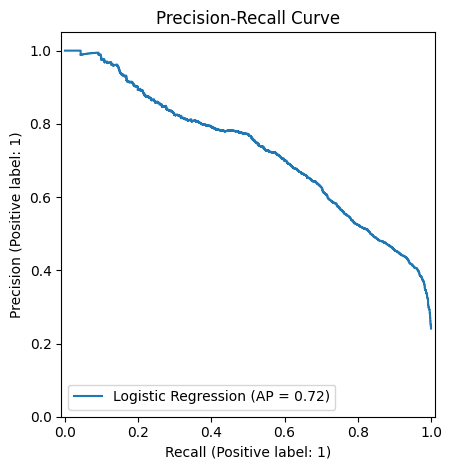

In [ ]:
# your code here
model = LogisticRegression(max_iter=1000, random_state=777)
model.fit(X_train_encoded, y_train)

y_pred_proba = model.predict_proba(X_test_encoded)[:, 1]

plot_pr_curve(y_test, y_pred_proba, classifier_name='Logistic Regression')

Допустим, мы хотим оставить только 40 лучших признаков.

Заметим, что нельзя оценивать качество по тестовой выборке, иначе мы можем переобучиться, как, например, при настройке гиперпараметров. Разделите обучающую выборку на 2 части, одну из которых, используйте для валидации. Исходную тестовую выборку стоит использовать только для финальной оценки качества после процедуры фильтрации

In [ ]:
# your code here
X_train, X_val, y_train, y_val = train_test_split(X_train_encoded, y_train, test_size=0.2, random_state=777, stratify=y_train)

Попробуем сделать это следующими способами:

#### __Задание 9. Встроенные методы (0.5 балла)__

Начнём с отбора признаков с помощью модели. У разных алгоритмов есть разные встроенные способы оценки вклада признаков в предсказание. Как известно, у линейной модели за это отвечают веса, а значит, их модуль можно интерпретировать как важность. Такой метод отбора называются встроенным или embedded method, так как он заложен в особенности модели.

Оставьте 40 признаков с наибольшим модулем соответствующего параметра линейной модели. Обучите модели заново и оцените её качество. Замерьте скорость такого отбора признаков.



Обучение логистической регрессии на всех признаках...


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Обучение на всех признаках заняло 3.093 сек.

Обучение модели на отобранных 40 признаках...
Время обучения на 40 признаках: 0.079 сек.
Logistic Regression metrics
AUC-PR: 0.4761


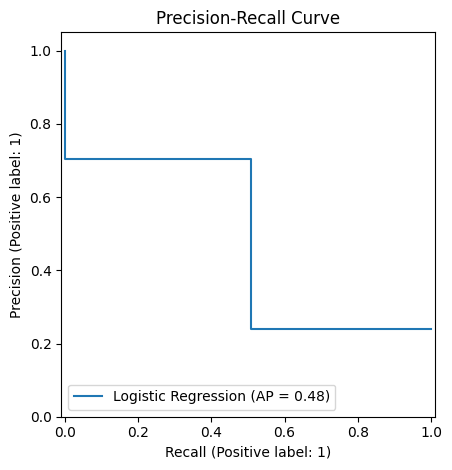

In [ ]:
# your code here
print("Обучение логистической регрессии на всех признаках...")
start_all = time.time()
lr_all = LogisticRegression(max_iter=1000, random_state=777)
lr_all.fit(X_train, y_train)
time_all = time.time() - start_all
print(f"Обучение на всех признаках заняло {time_all:.3f} сек.")

coef_abs = abs(lr_all.coef_[0])
top40_idx = coef_abs.argsort()[-40:][::-1]

X_train_40 = X_train[:, top40_idx]
X_val_40 = X_val[:, top40_idx]

print("\nОбучение модели на отобранных 40 признаках...")
start_sel = time.time()
lr_sel = LogisticRegression(max_iter=1000, random_state=777)
lr_sel.fit(X_train_40, y_train)
time_sel = time.time() - start_sel
print(f"Время обучения на 40 признаках: {time_sel:.3f} сек.")

y_val_pred = lr_sel.predict(X_val_40)

plot_pr_curve(y_val, y_val_pred, classifier_name='Logistic Regression')

Изменилось ли качество? Как?

Подумаем, что мы не учли. Мы действовали в предположении, что признаки вносят вклад равномерно, и не учитывали их масштаб. Если мы умножим один из признаков в 100 раз, то без учёта регуляризации его вес уменьшится в эти же 100 раз. А мы на основе этого отбираем признаки! Давайте сначала отмасштабируем признаки одним из способов, а только потом будем удалять признаки.

Помните, что не все способы одинаково хороши, особенно в условиях наличия выбросов

Кстати, в таком случае надо пересчитать качество на всех признаках (сделайте это ниже). Если вы сделали нормирование признаков в самом начале, то попробуйте отобрать признаки на неотмасштабированных данных.

Что получилось?

Logistic Regression metrics
AUC-PR: 0.5339


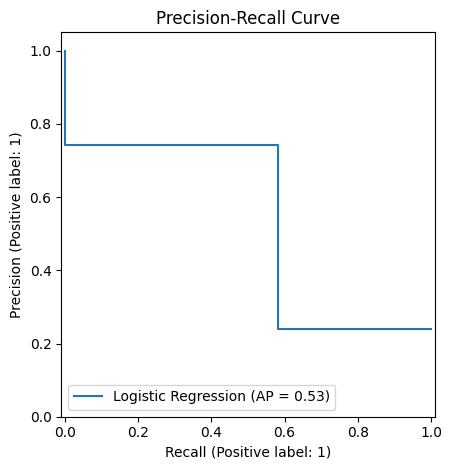

In [ ]:
# your code here
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler(with_mean=False)
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)


lr_all = LogisticRegression(max_iter=1000, random_state=777)
lr_all.fit(X_train_scaled, y_train)

coef_abs = abs(lr_all.coef_[0])
top40_idx = coef_abs.argsort()[-40:][::-1]

X_train_40 = X_train_scaled[:, top40_idx]
X_val_40 = X_val_scaled[:, top40_idx]

lr_sel = LogisticRegression(max_iter=1000, random_state=777)
lr_sel.fit(X_train_40, y_train)

y_val_pred = lr_sel.predict(X_val_40)

plot_pr_curve(y_val, y_val_pred, classifier_name='Logistic Regression')

#### __Задание 10. Методы фильтрации (0.5 балла)__


Давайте отбирать признаки умнее, а именно через подсчёт некоторой функции для каждого признака. На основании значений этой функции будем оставлять наиболее важные признаки. Методы этого семейства называют фильтрующими или  filter methods.

Одна из самых простых функция - корреляция между признаком и целевой переменной. Подумайте, какая взаимосвязь между корреляцией и предсказательной способностью модели, и как бы вы использовали информацию о корреляции для отбора признаков

**Ответ:** # your code here

Посчитайте корреляцию каждого признака с таргетом и отфильтруйте 40 признаков исходя из того, что вы описали, после чего замерьте качество и время отбора



/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Общее время отбора и обучения: 11.5698 сек
Logistic Regression metrics
AUC-PR: 0.5311


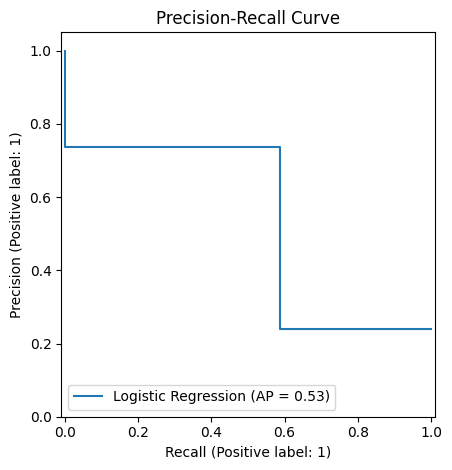

In [ ]:
# your code here
from scipy.stats import pearsonr

start_corr = time.time()
correlations = np.array([pearsonr(X_train[:, i], y_train)[0] for i in range(X_train.shape[1])])

abs_corr = np.abs(correlations)
corr_time = time.time() - start_corr

top40_corr_idx = np.argsort(abs_corr)[-40:][::-1]

X_train_corr = X_train[:, top40_corr_idx]
X_val_corr = X_val[:, top40_corr_idx]

start_train = time.time()
lr_corr = LogisticRegression(max_iter=1000, random_state=777)
lr_corr.fit(X_train_corr, y_train)
train_time = time.time() - start_train

y_val_pred = lr_corr.predict(X_val_corr)

total_time = corr_time + train_time
print(f"Общее время отбора и обучения: {total_time:.4f} сек")

plot_pr_curve(y_val, y_val_pred, classifier_name='Logistic Regression')

В качестве еще одной функция можно считать t-статистику:

$$t(j) = \frac{|\mu_+ - \mu_-|}{\sqrt{\frac{n_+ \sigma^2_+ + n_- \sigma^2_-}{n_+ + n_-}}},$$

где $\mu$, $\sigma$, $n$ соответственно среднее, стандартное отклонение и количество объектов каждого из классов.

Оставьте 40 признаков с наибольшим значением $t$, замерьте качество и скорость отбора признаков.

/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Общее время: 10.4386 сек
Logistic Regression metrics
AUC-PR: 0.5311


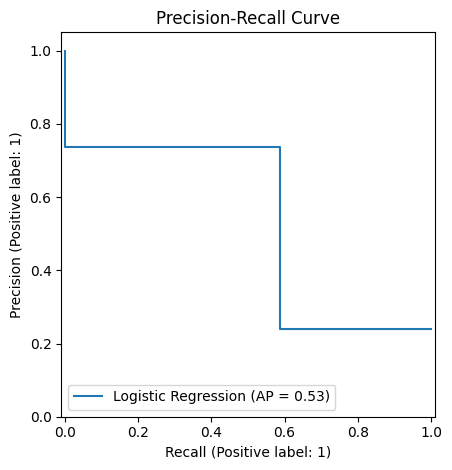

In [ ]:
# your code here
def compute_t_statistic(X, y):
    """
    X: numpy array (n_samples, n_features)
    y: numpy array (n_samples,) с бинарными метками (0/1)
    Возвращает массив t(j) для каждого признака.
    """
    X_pos = X[y == 1]
    X_neg = X[y == 0]
    n_pos = X_pos.shape[0]
    n_neg = X_neg.shape[0]

    mean_pos = np.mean(X_pos, axis=0)
    mean_neg = np.mean(X_neg, axis=0)
    std_pos = np.std(X_pos, axis=0, ddof=0)
    std_neg = np.std(X_neg, axis=0, ddof=0)

    numerator = np.abs(mean_pos - mean_neg)
    denominator = np.sqrt((n_pos * std_pos**2 + n_neg * std_neg**2) / (n_pos + n_neg))

    t_vals = np.divide(numerator, denominator, out=np.zeros_like(numerator), where=denominator != 0)
    return t_vals

start_total = time.time()

start_t = time.time()
t_values = compute_t_statistic(X_train, y_train)
time_t = time.time() - start_t

top40_t_idx = np.argsort(t_values)[-40:][::-1]

X_train_t = X_train[:, top40_t_idx]
X_val_t = X_val[:, top40_t_idx]

start_train = time.time()
lr_t = LogisticRegression(max_iter=1000, random_state=777)
lr_t.fit(X_train_t, y_train)
time_train = time.time() - start_train

total_time = time_t + time_train

y_val_pred = lr_t.predict(X_val_t)
print(f"Общее время: {total_time:.4f} сек")

plot_pr_curve(y_val, y_val_pred, classifier_name='Logistic Regression')

# Часть 4. Оценка экономического эффекта модели (2 балла)



В данной части мы займемся тем, что от вас скорее всего потребуется на реальной работе (помимо перекладки `json`, разумеется). А именно:
- мы соберем несколько специализированных метрик качества,
- попытаемся настроить модель на максимизацию _прибыли_,
- оценим, сколько вообще получится заработать на этом.

Разумеется, здесь будет сделано множество упрощающих жизнь допущений, но обо всем по порядку. Если вы всё прослушали на экономике, то напомним, что выручка — это сколько денег нам принесли клиенты, а прибыль — выручка за вычетом расходов на зарплату и прочее.


#### __Задание 12. Прогноз по доходам и расходам__ (1 балл)

В этой части мы будем работать с данными [UCI Bank Marketing Dataset](https://archive.ics.uci.edu/ml/datasets/bank+marketing). Этот датасет содержит информацию о банковском телефонном маркетинге.

__Объектом__ здесь является телефонный звонок потенциальному клиенту с предложением некоторой услуги (утверждается, что это краткосрочный депозит). В качестве признакового описания используются характеристики клиента (образование, брак и т.д.), данные о звонке и различные экономические индикаторы - более подробная информация представлена в файле `bank-additional-names.txt`.
__Целевая переменная__ - ответ клиента (согласился ли он открыть депозит?)

In [ ]:
!wget https://archive.ics.uci.edu/ml/machine-learning-databases/00222/bank-additional.zip
!unzip bank-additional.zip
df = pd.read_csv('bank-additional/bank-additional-full.csv', sep=';')

In [ ]:
df.head()

In [ ]:
X = df.drop(columns=['duration', 'y'])
y = (df.y == 'yes')

В этой части не нужно делить выборку - мы будем использовать кросс-валидацию.  Используйте наиболее подходящие с вашей точки зрения параметры и их значения (`shuffle`, `stratify`, число фолдов, ...). По кросс-валидации у вас получится несколько вариантов обучающей и тестовой выборки. Для удобства можно воспользоваться шаблоном ниже, который по ходу выполнения задания будет обрастать функционалом. Как обычно, это необязательно, но сохранять результаты экспериментов очень и очень желательно, в конце мы будем их сравнивать

In [ ]:
from collections import defaultdict
from sklearn.model_selection import KFold

def cross_validate(
    X,
    y,
    n_splits=5,
    random_state=None,
    shuffle=False,
    # другие аргументы, которые могут вам пригодиться дальше по пунктам
):
    metrics = []
    # или любой другой фолд, посмотрите в model_selection
    kf = KFold(n_splits=n_splits, random_state=random_state, shuffle=shuffle)

    for train_index, test_index in kf.split(X):

        # возьмите датасет и обучите модель
        # your code here

        # посчитайте метрики, которые вам нужны и добавьте результаты с каждого фолда
        metric_dict = {
            # "metric_key": metric_value
        }
        metrics.append(metric_dict)

    # осталось только красиво всё обернуть
    return pd.DataFrame(metrics)